# Solana AMM take-profit v2: more data, per-token take-profit, expected-value policy

This notebook builds on `solana-amm-microstructure-take-profit-modeling.ipynb` (v1). The features and the
two-stage LightGBM cascade are the same. Four things change:

1. **More labelled data.** `train_archive.csv` (older labelled days that v1 never loaded) is added to `train.csv`,
   giving about 2.5x the training tokens and a longer wallet-reputation history.
2. **One cascade per take-profit level.** Stage 2 is trained for every tp in the ladder
   (3, 4, 5, 7, 10, 20x), not only 5x. The 5x score is exactly the v1 model.
3. **Per-token take-profit by expected value.** Scores are calibrated into probabilities P(max_x >= k) and each
   token gets the tp with the highest expected PnL, `p_k * (k - 1 - 0.30) + (1 - p_k) * average_miss_loss_k`.
   A token is traded only if that EV clears a margin, with a daily cap.
4. **Honest evaluation.** A longer embargoed walk-forward. Calibration, the miss-loss estimate, the EV margin
   and the daily cap (and, for the baselines, the depth and tp) are all chosen **using earlier days only**,
   so the reported PnL is not the best cell picked after the fact.

Competition rules are unchanged: one decision per token at t = 60 s, tp = 0 or 3 <= tp <= 100, 1 SOL per trade,
0.30 SOL cost, a miss is settled at the 1-hour price.

In [1]:
import os, sys, glob, time, re, gc, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# Competition constants
COST = 0.30          # flat cost per trade (SOL)
WIN = 3600           # 1h holding horizon (s)
EMBARGO = 3600       # extra gap between training labels and validation day (s)
TARGET_K = 5.0       # threshold used by the wallet-reputation features (unchanged from v1)
TP_MIN, TP_MAX = 3.0, 100.0

# Take-profit ladder the EV policy can choose from
TP_LADDER = [3.0, 4.0, 5.0, 7.0, 10.0, 20.0]
SURVIVE_K = 1.5      # stage-1 "survival" threshold of the cascade

# Walk-forward settings
MIN_TRAIN_DAYS = 15  # first evaluation day needs at least this many labelled days before it
CALIB_WARMUP_DAYS = 10  # evaluation days used only to fit calibration before the policy trades
N_SEEDS = 5          # LightGBM seeds per model (lower to 3 for a faster run)

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})
print(f"Python {sys.version.split()[0]} | lightgbm {lgb.__version__} | pandas {pd.__version__}")


Python 3.13.18 | lightgbm 4.7.0 | pandas 3.0.5


## Data
`train.csv` and `train_archive.csv` are combined into one labelled set. The trade tapes cover every labelled day, so all features can be built for the archive tokens too.

In [2]:
CANDIDATE_PATHS = [
    '/kaggle/input/competitions/memecoins-pump-or-dump',
    '/kaggle/input/memecoins-pump-or-dump',
    'memecoins-pump-or-dump',
    'data',
]
DATA_DIR = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_DIR is None:
    raise FileNotFoundError("Competition data not found. Add the competition as an input.")
print(f"Data directory: {DATA_DIR}")

def _norm(df):
    if 'final_x' not in df.columns and 'finalx' in df.columns:
        df['final_x'] = df['finalx']
    df['day'] = pd.to_datetime(df['mt'], unit='s').dt.strftime('%Y-%m-%d')
    return df

# NEW in v2: train.csv (latest 30 days) + train_archive.csv (older labelled days)
train_recent = _norm(pd.read_csv(os.path.join(DATA_DIR, 'train.csv')))
archive_path = os.path.join(DATA_DIR, 'train_archive.csv')
if os.path.exists(archive_path):
    train_archive = _norm(pd.read_csv(archive_path))
else:
    train_archive = train_recent.iloc[:0].copy()
    print("WARNING: train_archive.csv not found; training on train.csv only.")
train_recent['src'] = 'train'
train_archive['src'] = 'archive'
train_df = (pd.concat([train_archive, train_recent], ignore_index=True)
              .drop_duplicates('mint', keep='last')
              .sort_values('mt').reset_index(drop=True))

test_df = _norm(pd.read_csv(os.path.join(DATA_DIR, 'test.csv')))
sample_sub_df = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))
migrations_df = pd.read_csv(os.path.join(DATA_DIR, 'pfamm_migrations.csv'))
creation_df = pd.read_csv(os.path.join(DATA_DIR, 'pumpfun_token_creation.csv')).drop_duplicates('mint')
rank_path = os.path.join(DATA_DIR, 'ranking_history.csv')
ranking_df = pd.read_csv(rank_path) if os.path.exists(rank_path) else None

if os.path.exists(os.path.join(DATA_DIR, 'trades')):
    TAPE_DAYS = [(d.split('=')[-1], os.path.join(d, 'pumpfun_all_swaps.parquet'),
                  os.path.join(d, 'pumpswap_all_swaps.parquet'))
                 for d in sorted(glob.glob(os.path.join(DATA_DIR, 'trades', 'day=*')))]
else:
    TAPE_DAYS = [(os.path.basename(f)[4:14], f, f.replace('pumpfun_all_swaps', 'pumpswap_all_swaps'))
                 for f in sorted(glob.glob(os.path.join(DATA_DIR, 'day_*_pumpfun_all_swaps.parquet')))]

print(f"train.csv:         {len(train_recent):6,} tokens  {train_recent['day'].min()} -> {train_recent['day'].max()}")
print(f"train_archive.csv: {len(train_archive):6,} tokens  {train_archive['day'].min() if len(train_archive) else '-'} -> {train_archive['day'].max() if len(train_archive) else '-'}")
print(f"Combined labelled: {len(train_df):6,} tokens over {train_df['day'].nunique()} days")
print(f"Test:              {len(test_df):6,} tokens on {test_df['day'].iloc[0]}")
print(f"Trade-tape days:   {len(TAPE_DAYS)}")
print("Base rates (combined):", {f'>={k:g}x': f"{(train_df['max_x'] >= k).mean():.2%}" for k in TP_LADDER})


Data directory: data


train.csv:         16,161 tokens  2026-10-02 -> 2026-10-31
train_archive.csv: 24,732 tokens  2026-08-21 -> 2026-10-01
Combined labelled: 40,893 tokens over 72 days
Test:                 409 tokens on 2026-11-01
Trade-tape days:   73
Base rates (combined): {'>=3x': '13.03%', '>=4x': '7.74%', '>=5x': '5.00%', '>=7x': '2.59%', '>=10x': '1.35%', '>=20x': '0.33%'}


## Features (unchanged from v1)
First-minute AMM flow, bonding-curve statistics and creation/bundle metadata. The tapes stop at `ts_rel = 60`, so nothing after the decision time is used.

In [3]:
# Vectorized High-Frequency Microstructure Feature Extraction Engine
CURVE_COLS = ['failed', 'mint', 'ts_rel', 'slot', 'tx_idx', 'direction', 'sol', 'tok', 'wallet', 'new_price']
AMM_COLS   = ['mint', 'ts_rel', 'slot', 'tx_idx', 'direction', 'sol', 'tok', 'signing_wallet', 'new_price']

def extract_tape_features(c_df, a_df):
    # High-frequency microstructure metrics from bonding curve and AMM tapes
    # Invariant: Prices taken from pool reserves (new_price), not sol/tok ratios
    # Invariant: AMM direction is normalized to token ('B' = buy token, 'S' = sell token)
    for df in (c_df, a_df):
        df['is_buy'] = df['direction'].astype(str).str.upper().str.startswith('B').astype(np.int8)
        df['price'] = np.where(df['new_price'] > 0, df['new_price'], df['sol'] / np.maximum(df['tok'], 1e-18))

    # Stable sort by mint, slot, tx_idx preserving exact chain order and intra-tx swap file order
    # Invariant: NEVER sort by ts or block_time, as doing so scrambles trades within the same second
    a_df = a_df.sort_values(['mint', 'slot', 'tx_idx'], kind='mergesort')
    g_amm = a_df.groupby('mint')
    
    F = pd.DataFrame(index=g_amm.size().index)
    
    # 1. AMM Participation & Volume
    F['amm_n'] = g_amm.size()
    F['amm_sol'] = g_amm['sol'].sum()
    F['amm_uw'] = g_amm['wallet'].nunique()
    F['trades_per_wallet'] = F['amm_n'] / F['amm_uw'].replace(0, np.nan)
    
    # Participant concentration (Top-1 wallet volume share and HHI)
    wallet_sol = a_df.groupby(['mint', 'wallet'])['sol'].sum()
    wallet_tot = wallet_sol.groupby('mint').sum().replace(0, np.nan)
    F['amm_top1'] = wallet_sol.groupby('mint').max() / wallet_tot
    
    # Herfindahl-Hirschman Index (HHI)
    wallet_shares_sq = (wallet_sol / wallet_sol.groupby('mint').transform('sum').replace(0, np.nan)) ** 2
    F['amm_hhi'] = wallet_shares_sq.groupby('mint').sum()
    
    # 2. Temporal Flow Dynamics (Early vs. Late)
    late_mask = a_df['ts_rel'] >= 45
    early_mask = a_df['ts_rel'] < 15
    late_df = a_df[late_mask]
    early_df = a_df[early_mask]
    
    F['late_sol'] = late_df.groupby('mint')['sol'].sum()
    early_sol = early_df.groupby('mint')['sol'].sum().replace(0, np.nan)
    F['late_over_early'] = F['late_sol'] / early_sol
    
    late_buys = late_df[late_df['is_buy'] == 1]
    F['late_buyshare'] = late_buys.groupby('mint')['sol'].sum() / F['late_sol'].replace(0, np.nan)
    
    tail_df = a_df[a_df['ts_rel'] > 30]
    tail_buys = tail_df[tail_df['is_buy'] == 1]
    F['tail_buyshare'] = tail_buys.groupby('mint')['sol'].sum() / tail_df.groupby('mint')['sol'].sum().replace(0, np.nan)
    
    # Fresh wallet arrivals in terminal window
    early_wallets = early_df.groupby('mint')['wallet'].apply(set)
    late_wallets = late_df.groupby('mint')['wallet'].apply(set)
    F['fresh_wallets'] = pd.Series({
        m: len(s - early_wallets.get(m, set())) for m, s in late_wallets.items()
    })
    
    # 3. Predatory Fast Flipping Detection
    early_buyers = a_df[(a_df['ts_rel'] <= 15) & (a_df['is_buy'] == 1)].groupby('mint')['wallet'].apply(set)
    first_min_sellers = a_df[a_df['is_buy'] == 0].groupby('mint')['wallet'].apply(set)
    F['flip_rate'] = pd.Series({
        m: len(s & first_min_sellers.get(m, set())) / max(len(s), 1) for m, s in early_buyers.items()
    })
    
    # 4. Order Size & Whale Participation
    buys_df = a_df[a_df['is_buy'] == 1]
    F['buy_max'] = buys_df.groupby('mint')['sol'].max()
    F['whale_buys'] = buys_df[buys_df['sol'] >= 5.0].groupby('mint').size().reindex(F.index).fillna(0)
    F['buy_count'] = buys_df.groupby('mint').size().reindex(F.index).fillna(0)
    F['sell_count'] = (F['amm_n'] - F['buy_count']).fillna(0)
    F['net_buy_ratio'] = (F['buy_count'] - F['sell_count']) / F['amm_n'].replace(0, np.nan)
    
    # 5. Price Path & Microstructure Drawdown (from reserve new_price)
    p_first = g_amm['price'].first()
    p_last = g_amm['price'].last()
    p_max = g_amm['price'].max()
    
    F['ret60'] = p_last / p_first.replace(0, np.nan)
    F['runup'] = p_max / p_first.replace(0, np.nan)
    F['at_high'] = p_last / p_max.replace(0, np.nan)
    F['drawdown_from_peak'] = 1.0 - F['at_high']
    F['vol'] = a_df.assign(lp=np.log(a_df['price'].replace(0, np.nan))).groupby('mint')['lp'].std()
    
    # Kyle's Lambda Microstructure Price Impact Proxy
    aa = a_df[a_df['price'] > 0].copy()
    aa['dlp'] = aa.groupby('mint')['price'].transform(lambda s: np.log(s).diff())
    aa['signed_sol'] = np.where(aa['is_buy'] == 1, aa['sol'], -aa['sol'])
    aa = aa.dropna(subset=['dlp'])
    F['impact_per_sol'] = ((aa['signed_sol'] * aa['dlp']).groupby(aa['mint']).sum()
                           / (aa['signed_sol'] ** 2).groupby(aa['mint']).sum().replace(0, np.nan))
    
    # 6. Bonding Curve Dynamics & Latent Failed Instructions
    ok_curve = c_df[c_df['failed'] == 0]
    g_curve = ok_curve.groupby('mint')
    F['curve_sol'] = g_curve['sol'].sum()
    F['curve_uw'] = g_curve['wallet'].nunique()
    F['curve_dur'] = -g_curve['ts_rel'].first()
    F['curve_failed'] = c_df[c_df['failed'] != 0].groupby('mint').size().reindex(F.index).fillna(0)
    F['curve_failed_ratio'] = F['curve_failed'] / (F['curve_failed'] + ok_curve.groupby('mint').size().reindex(F.index).fillna(0))
    F['migration_pop'] = p_first / g_curve['price'].last().replace(0, np.nan)
    
    # Reconstructed helper columns per 2026-10-01 competition dataset specification
    F['pre_failed'] = F['curve_failed']
    curve_ok_trades = ok_curve.groupby('mint').size().reindex(F.index).fillna(0)
    amm_trades_pos = a_df[a_df['new_price'] > 0].groupby('mint').size().reindex(F.index).fillna(0)
    F['pre_total'] = curve_ok_trades + amm_trades_pos
    F['entry'] = (g_amm['new_price'].last() / 1000.0).reindex(F.index)
    
    return F

# Check if cached features exist locally, else compute across all partitions
if os.path.exists('tape_features.feather'):
    print("Loading precomputed high-frequency tape features from tape_features.feather...")
    TAPE_FEATURES_DF = pd.read_feather('tape_features.feather')
    print(f"Loaded master tape feature matrix: {TAPE_FEATURES_DF.shape}")
else:
    print("Extracting high-frequency tape features across daily partitions...")
    t_start = time.time()
    tape_frames = []

    for idx, (day_str, curve_path, amm_path) in enumerate(TAPE_DAYS, 1):
        c_part = pd.read_parquet(curve_path, columns=CURVE_COLS)
        a_part = pd.read_parquet(amm_path, columns=AMM_COLS).rename(columns={'signing_wallet': 'wallet'})
        
        day_features = extract_tape_features(c_part, a_part)
        tape_frames.append(day_features.reset_index().rename(columns={'index': 'mint'}))
        
        del c_part, a_part
        gc.collect()
        if idx % 10 == 0 or idx == len(TAPE_DAYS):
            print(f"Processed {idx:2d}/{len(TAPE_DAYS)} days ({time.time() - t_start:.1f}s elapsed)")

    TAPE_FEATURES_DF = pd.concat(tape_frames, ignore_index=True)
    print(f"Master tape feature matrix constructed: {TAPE_FEATURES_DF.shape} in {time.time() - t_start:.1f}s")


Extracting high-frequency tape features across daily partitions...


Processed 10/73 days (24.6s elapsed)


Processed 20/73 days (37.6s elapsed)


Processed 30/73 days (49.0s elapsed)


Processed 40/73 days (66.5s elapsed)


Processed 50/73 days (90.1s elapsed)


Processed 60/73 days (105.5s elapsed)


Processed 70/73 days (115.4s elapsed)


Processed 73/73 days (118.4s elapsed)
Master tape feature matrix constructed: (41354, 33) in 118.4s


In [4]:
# Parse Token Creation Metadata & Structural Bundle Footprints
name_s = creation_df['name'].fillna('').astype(str)
sym_s = creation_df['symbol'].fillna('').astype(str)
bs_s = creation_df['bundle_structure'].fillna('').astype(str)

LAUNCH_M = pd.DataFrame({'mint': creation_df['mint']})
LAUNCH_M['name_len'] = name_s.str.len()
LAUNCH_M['symbol_len'] = sym_s.str.len()
LAUNCH_M['name_upper_ratio'] = name_s.apply(lambda s: sum(ch.isupper() for ch in s) / max(len(s), 1))
LAUNCH_M['name_eq_symbol'] = (name_s.str.lower().str[:4] == sym_s.str.lower().str[:4]).astype(int)

# Parsing bundle operations and capital commitment
LAUNCH_M['bs_ops'] = bs_s.str.split().str.len()
LAUNCH_M['bs_buys'] = bs_s.apply(lambda s: len(re.findall(r'\dB\d', s)))
amt_extracted = bs_s.apply(lambda s: [int(x) for x in re.findall(r':(\d{6,})', s)])
LAUNCH_M['bs_amt_sum'] = amt_extracted.apply(lambda v: float(np.sum(v)) if v else 0.0)
LAUNCH_M['bs_amt_max'] = amt_extracted.apply(lambda v: float(np.max(v)) if v else 0.0)

# Numerical instruction and execution profile fields
numerical_cols = [
    'gas_used', 'amount_of_instructions', 'amount_of_lookup_reads', 'amount_of_lookup_writes',
    'creation_ix_index', 'pf_program_index', 'direct_pf_invocation', 'is_cashback_enabled',
    'bundle_size', 'bundled_buys', 'bundled_buys_count', 'dev_balance'
]
for col_name in numerical_cols:
    if col_name in creation_df.columns:
        LAUNCH_M[col_name] = pd.to_numeric(creation_df[col_name], errors='coerce').values

LAUNCH_M['token2022'] = (~creation_df['token_program'].fillna('').astype(str).str.startswith('Tokenkeg')).astype(int)
LAUNCH_M['created_ts'] = creation_df['created_ts'].values

# Feature assembly pipeline
def assemble_feature_table(base_df):
    merged = base_df.merge(TAPE_FEATURES_DF, on='mint', how='left').merge(LAUNCH_M, on='mint', how='left')
    merged['age_s'] = merged['mt'] - merged['created_ts']
    return merged.sort_values('mt').reset_index(drop=True)

TR_DF = assemble_feature_table(train_df)
TE_DF = assemble_feature_table(test_df)

# Backward compatibility: Merge reconstructed helper features back into train_df and test_df
for helper_c in ['entry', 'pre_total', 'pre_failed']:
    if helper_c in TAPE_FEATURES_DF.columns:
        if helper_c not in train_df.columns:
            train_df[helper_c] = train_df['mint'].map(TAPE_FEATURES_DF.set_index('mint')[helper_c])
        if helper_c not in test_df.columns:
            test_df[helper_c] = test_df['mint'].map(TAPE_FEATURES_DF.set_index('mint')[helper_c])

BASE_FEATURE_COLS = [
    c for c in list(TAPE_FEATURES_DF.columns) + list(LAUNCH_M.columns)
    if c not in ('mint', 'created_ts', 'entry')
] + ['age_s']

# Ensure pre_total and pre_failed are explicitly retained in BASE_FEATURE_COLS
for req_c in ['pre_total', 'pre_failed']:
    if req_c not in BASE_FEATURE_COLS:
        BASE_FEATURE_COLS.append(req_c)

print(f"Base feature matrix constructed: {len(BASE_FEATURE_COLS)} features")
print(f"Training observations: {len(TR_DF):,} | Test observations: {len(TE_DF):,}")


Base feature matrix constructed: 53 features
Training observations: 40,893 | Test observations: 409


### Leak-free wallet reputation (unchanged from v1)
A token's outcome only feeds wallet statistics once it has resolved (`mt + 1h`). With the archive included, the history starts about six weeks earlier.

In [5]:
# Leak-Free Causal Participant Reputation Engine
t0_rep = time.time()
print("Extracting first-minute buyer wallet graphs across AMM tapes...")

# Ingest minimal buyer edge records across all daily AMM tapes
AMM_MIN_COLS = ['mint', 'ts_rel', 'slot', 'tx_idx', 'direction', 'sol', 'signing_wallet']
wallet_edges = []

for _, _, amm_p in TAPE_DAYS:
    a_min = pd.read_parquet(amm_p, columns=AMM_MIN_COLS).rename(columns={'signing_wallet': 'wallet'})
    a_buys = a_min[a_min['direction'].astype(str).str.upper().str.startswith('B') & (a_min['ts_rel'] <= 60)]
    wallet_edges.append(a_buys.groupby(['mint', 'wallet'], as_index=False)['sol'].sum())
    del a_min, a_buys
    gc.collect()

EDGE_DF = pd.concat(wallet_edges, ignore_index=True)
EDGE_DF['wid'] = EDGE_DF['wallet'].astype('category').cat.codes.astype(np.int64)

# Map token mints to participant wallet arrays and SOL volume
by_mint_wallets = {
    m: (g['wid'].values, g['sol'].values)
    for m, g in EDGE_DF.sort_values('mint').groupby('mint', sort=False)
}
num_wallets = int(EDGE_DF['wid'].max()) + 1

print(f"Wallet graph mapped: {len(EDGE_DF):,} edges across {num_wallets:,} unique wallets ({time.time()-t0_rep:.1f}s)")

# Assemble combined chronological token timeline
tok_timeline = pd.concat([
    TR_DF[['mint', 'mt', 'max_x']],
    TE_DF[['mint', 'mt']].assign(max_x=np.nan)
], ignore_index=True).sort_values('mt').reset_index(drop=True)

# State accumulators for sequential causal processing
nW = num_wallets
appear = np.zeros(nW, np.int32)
hit = np.zeros(nW, np.int32)

t_mints = tok_timeline['mint'].values
t_mts   = tok_timeline['mt'].values
t_mxs   = tok_timeline['max_x'].values
N_tokens = len(tok_timeline)

REPUTATION_FEATURE_NAMES = ['w_known', 'w_hit_max', 'w_hit_mean', 'w_hit_top3', 'w_elite_n', 'w_elite_share', 'w_eb_score']
rep_matrix = np.zeros((N_tokens, len(REPUTATION_FEATURE_NAMES)), dtype=np.float32)

j = 0
C_PRIOR = 10.0
P_PRIOR = 0.06

for i in range(N_tokens):
    # Commit only tokens that have fully resolved under 1-hour embargo (mt + 3600s)
    while j < N_tokens and t_mts[j] <= t_mts[i] - WIN:
        if not np.isnan(t_mxs[j]):
            w = by_mint_wallets.get(t_mints[j])
            if w is not None:
                np.add.at(appear, w[0], 1)
                if t_mxs[j] >= TARGET_K:
                    np.add.at(hit, w[0], 1)
        j += 1
        
    w = by_mint_wallets.get(t_mints[i])
    if w is None:
        continue
        
    wids, sols = w
    ap = appear[wids]
    known = ap >= 3
    if known.sum() == 0:
        continue
        
    rates = hit[wids][known] / ap[known]
    elite = (ap >= 5) & (hit[wids] >= 1)
    tot_sol = sols.sum()
    elite_share = sols[elite].sum() / max(tot_sol, 1e-9)
    eb_rates = (hit[wids][known] + C_PRIOR * P_PRIOR) / (ap[known] + C_PRIOR)
    
    rep_matrix[i] = [
        int(known.sum()),
        float(rates.max()),
        float(rates.mean()),
        float(np.sort(rates)[-3:].mean()),
        int(elite.sum()),
        float(elite_share),
        float(eb_rates.max())
    ]

REP_DF = pd.DataFrame(rep_matrix, columns=REPUTATION_FEATURE_NAMES)
REP_DF['mint'] = t_mints

# Merge reputation signals into training and test datasets
TR_DF = TR_DF.merge(REP_DF, on='mint', how='left')
TE_DF = TE_DF.merge(REP_DF, on='mint', how='left')

ALL_FEATURE_COLS = [c for c in BASE_FEATURE_COLS if c in TR_DF.columns] + REPUTATION_FEATURE_NAMES
print(f"Reputation features merged successfully in {time.time()-t0_rep:.1f}s.")
print(f"Total features available for modeling: {len(ALL_FEATURE_COLS)}")


Extracting first-minute buyer wallet graphs across AMM tapes...


Wallet graph mapped: 8,640,165 edges across 1,427,138 unique wallets (38.9s)


Reputation features merged successfully in 42.6s.
Total features available for modeling: 60


## Model: cascade for every take-profit level
`s_k = P(max_x >= 1.5) x P(max_x >= k | max_x >= 1.5)`. Stage 1 is shared; stage 2 is fitted separately for each k.

In [6]:
def pnl_vec(tp, max_x, final_x, fee=COST):
    """Competition PnL per token: tp=0 skip; hit -> tp-1-fee; miss -> max(final_x-1-fee, -1)."""
    tp = np.asarray(tp, float); mx = np.asarray(max_x, float); fx = np.asarray(final_x, float)
    miss = np.maximum(fx - 1.0 - fee, -1.0)
    return np.where(tp <= 0, 0.0, np.where(mx >= tp, tp - 1.0 - fee, miss))

LGB_PARAMS = dict(n_estimators=350, learning_rate=0.04, num_leaves=31, min_child_samples=45,
                  subsample=0.80, subsample_freq=1, colsample_bytree=0.70, n_jobs=4, verbose=-1)
SEEDS = [42, 101, 2024, 7, 777][:N_SEEDS]

def _fit_predict(X_tr, y, X_va):
    return np.mean([lgb.LGBMClassifier(random_state=s, **LGB_PARAMS).fit(X_tr, y).predict_proba(X_va)[:, 1]
                    for s in SEEDS], axis=0)

def multi_threshold_cascade(train, val, feature_cols, ladder=TP_LADDER):
    """Raw scores s_k = P(max_x>=1.5) * P(max_x>=k | max_x>=1.5) for every k in the ladder.
    s_5 is exactly the v1 model; s_3 is the 'stage 2 trained for 3x' variant."""
    X_tr = train[feature_cols].astype(float); X_va = val[feature_cols].astype(float)
    mx = train['max_x'].values
    surv = mx >= SURVIVE_K
    p_surv = _fit_predict(X_tr, surv.astype(int), X_va)
    out = {}
    for k in ladder:
        y = (mx[surv] >= k).astype(int)
        out[k] = p_surv * _fit_predict(X_tr[surv], y, X_va) if y.sum() >= 30 else p_surv * y.mean()
    return out
print(f"Model: two-stage cascade, ladder {TP_LADDER}, {len(SEEDS)} seeds, {1 + len(TP_LADDER)} models per fold")


Model: two-stage cascade, ladder [3.0, 4.0, 5.0, 7.0, 10.0, 20.0], 5 seeds, 7 models per fold


## Embargoed walk-forward
For each day, train on all tokens whose 1-hour outcome had resolved at least 1 hour before the day starts, then score that day. This is the slow step (about 7 models x seeds x days).

In [7]:
# Embargoed walk-forward: train on every labelled token resolved before (day start - 1h - 1h), predict the day.
ALL_DAYS = sorted(TR_DF['day'].unique())
EVAL_DAYS = ALL_DAYS[MIN_TRAIN_DAYS:]
print(f"Walk-forward over {len(EVAL_DAYS)} days: {EVAL_DAYS[0]} -> {EVAL_DAYS[-1]}")

if os.path.exists('oof_v2.parquet'):
    OOF = pd.read_parquet('oof_v2.parquet')
    print("Loaded cached out-of-fold scores (oof_v2.parquet)")
else:
    t0 = time.time(); parts = []
    for i, day in enumerate(EVAL_DAYS, 1):
        val = TR_DF[TR_DF['day'] == day].reset_index(drop=True)
        tr = TR_DF[(TR_DF['day'] < day) & (TR_DF['mt'] <= val['mt'].min() - WIN - EMBARGO)]
        s = multi_threshold_cascade(tr, val, ALL_FEATURE_COLS)
        d = val[['mint', 'day', 'mt', 'max_x', 'final_x']].copy()
        d['n_train'] = len(tr)
        for k, v in s.items():
            d[f's_{k:g}'] = v
        parts.append(d)
        if i % 5 == 0 or i == len(EVAL_DAYS):
            print(f"  {i:2d}/{len(EVAL_DAYS)} {day}  train={len(tr):,}  ({time.time()-t0:.0f}s)")
    OOF = pd.concat(parts, ignore_index=True)
    OOF.to_parquet('oof_v2.parquet', index=False)
print(f"Out-of-fold rows: {len(OOF):,}")


Walk-forward over 57 days: 2026-09-05 -> 2026-10-31


   5/57 2026-09-09  train=11,158  (103s)


  10/57 2026-09-14  train=12,986  (213s)


  15/57 2026-09-19  train=15,887  (329s)


  20/57 2026-09-24  train=19,204  (454s)


  25/57 2026-09-29  train=22,475  (589s)


... (3 outputs left out)

  45/57 2026-10-19  train=35,622  (1198s)


  50/57 2026-10-24  train=37,832  (1365s)


  55/57 2026-10-29  train=39,775  (1539s)


  57/57 2026-10-31  train=40,503  (1611s)
Out-of-fold rows: 31,481


## Calibration and EV policy, chosen on past days only

* **Calibration:** Platt scaling of each `s_k`, fitted on earlier walk-forward days only; probabilities are forced to fall as k rises.
* **Miss loss:** the average PnL of a miss at each tp, among the top 5% scored tokens of earlier days.
* **Policy settings:** each day uses the (margin, cap) with the best total PnL over *earlier* days.
  The v1-style baselines (top q% at one fixed tp) get the same treatment for their (q, tp).

In [8]:
from sklearn.linear_model import LogisticRegression

def _logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

def fit_calibration(hist, ladder=TP_LADDER):
    """Platt-scale each raw cascade score into a probability P(max_x >= k), using past out-of-fold days.
    Also estimate the average PnL of a miss at each tp among the higher-scored tokens."""
    cal, miss_loss = {}, {}
    for k in ladder:
        y = (hist['max_x'].values >= k).astype(int)
        lr = LogisticRegression(C=1.0).fit(_logit(hist[f's_{k:g}']), y) if 0 < y.sum() < len(y) else None
        cal[k] = lr
        top = hist[hist[f's_{k:g}'] >= hist.groupby('day')[f's_{k:g}'].transform(lambda s: s.quantile(0.95))]
        m = top[top['max_x'] < k]
        miss_loss[k] = float(pnl_vec(np.full(len(m), k), m['max_x'], m['final_x']).mean()) if len(m) >= 20 else -0.95
    return cal, miss_loss

def expected_values(df, cal, miss_loss, ladder=TP_LADDER):
    """Calibrated P(>=k) (forced non-increasing in k), EV per tp, and the EV-maximising tp per token."""
    P = np.column_stack([cal[k].predict_proba(_logit(df[f's_{k:g}']))[:, 1] if cal[k] is not None
                         else np.zeros(len(df)) for k in ladder])
    P = np.minimum.accumulate(P, axis=1)
    gain = np.array([k - 1.0 - COST for k in ladder]); loss = np.array([miss_loss[k] for k in ladder])
    EV = P * gain + (1 - P) * loss
    best = EV.argmax(axis=1)
    out = pd.DataFrame({'ev': EV[np.arange(len(df)), best], 'tp_ev': np.array(ladder)[best]}, index=df.index)
    for j, k in enumerate(ladder):
        out[f'p_{k:g}'] = P[:, j]
    return out

def apply_ev_policy(day_df, margin, cap_pct):
    """Trade tokens whose best EV exceeds `margin`, at most cap_pct% of the day's tokens (highest EV first)."""
    tp = np.zeros(len(day_df))
    cand = day_df.index[day_df['ev'].values > margin]
    if len(cand):
        cap = max(1, int(np.ceil(len(day_df) * cap_pct / 100)))
        keep = day_df.loc[cand, 'ev'].nlargest(cap).index
        tp[day_df.index.get_indexer(keep)] = day_df.loc[keep, 'tp_ev'].values
    return tp

# ---- Step 1: causal calibration. Each evaluation day uses only earlier days whose labels had resolved.
cal_days = EVAL_DAYS[CALIB_WARMUP_DAYS:]
ev_parts = []
for day in cal_days:
    day_start = OOF.loc[OOF['day'] == day, 'mt'].min()
    hist = OOF[(OOF['day'] < day) & (OOF['mt'] <= day_start - WIN)]
    cal, ml = fit_calibration(hist)
    d = OOF[OOF['day'] == day]
    ev_parts.append(pd.concat([d, expected_values(d, cal, ml)], axis=1))
EVDF = pd.concat(ev_parts).reset_index(drop=True)
print(f"Calibrated EV available for {EVDF['day'].nunique()} days: {cal_days[0]} -> {cal_days[-1]}")

# ---- Step 2: nested policy selection. Each day's (margin, cap) is chosen on earlier days only.
MARGIN_GRID = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
CAP_GRID = [1.0, 2.0, 3.0, 5.0]
FIXED_Q_GRID = [0.5, 1.0, 1.5, 2.0, 3.0]
FIXED_TP_GRID = [3.0, 4.0, 5.0, 7.0, 10.0]
SELECT_MIN_DAYS = 5

def topq_tp(day_df, score_col, q, tp):
    t = np.zeros(len(day_df)); n = max(1, int(len(day_df) * q / 100))
    t[np.argsort(-day_df[score_col].values)[:n]] = tp
    return t

days = sorted(EVDF['day'].unique())
by_day = {d: g.reset_index(drop=True) for d, g in EVDF.groupby('day')}

# PnL of every candidate setting on every day (computed once)
def _grid_pnl(fn, grid):
    return pd.DataFrame({p: [pnl_vec(fn(by_day[d], *p), by_day[d]['max_x'], by_day[d]['final_x']).sum()
                             for d in days] for p in grid}, index=days)
EV_GRID = _grid_pnl(apply_ev_policy, [(m, c) for m in MARGIN_GRID for c in CAP_GRID])
V1_GRID = _grid_pnl(lambda d, q, tp: topq_tp(d, 's_5', q, tp), [(q, tp) for q in FIXED_Q_GRID for tp in FIXED_TP_GRID])
B3_GRID = _grid_pnl(lambda d, q, tp: topq_tp(d, 's_3', q, tp), [(q, tp) for q in FIXED_Q_GRID for tp in FIXED_TP_GRID])

def nested_run(grid_pnl, fn, name):
    rows = []
    for i, d in enumerate(days):
        if i < SELECT_MIN_DAYS:
            continue
        best = grid_pnl.iloc[:i].sum().idxmax()     # chosen with earlier days only
        best = tuple(float(x) for x in best)
        dd = by_day[d]; tp = fn(dd, *best)
        pnl = pnl_vec(tp, dd['max_x'], dd['final_x'])
        traded = tp > 0
        rows.append({'policy': name, 'day': d, 'setting': str(best), 'trades': int(traded.sum()),
                     'hits': int((dd['max_x'].values >= tp)[traded].sum()), 'pnl': float(pnl.sum()),
                     'mean_tp': float(tp[traded].mean()) if traded.any() else np.nan})
    return pd.DataFrame(rows)

NESTED = pd.concat([
    nested_run(V1_GRID, lambda d, q, tp: topq_tp(d, 's_5', q, tp), 'v1: top-q, fixed tp (stage-2 @5x)'),
    nested_run(B3_GRID, lambda d, q, tp: topq_tp(d, 's_3', q, tp), 'top-q, fixed tp (stage-2 @3x)'),
    nested_run(EV_GRID, apply_ev_policy, 'v2: EV policy, per-token tp'),
], ignore_index=True)
REPORT_DAYS = sorted(NESTED['day'].unique())
print(f"Out-of-sample policy evaluation: {len(REPORT_DAYS)} days, {REPORT_DAYS[0]} -> {REPORT_DAYS[-1]}")


Calibrated EV available for 47 days: 2026-09-15 -> 2026-10-31


Out-of-sample policy evaluation: 42 days, 2026-09-20 -> 2026-10-31


## Results

=== Out-of-sample results, all report days (settings chosen on earlier days only) ===


,Policy,Days,Trades,Trades/day,Hit rate,Avg tp,Total PnL,PnL/trade,Profitable days,95% CI total
0,"v1: top-q, fixed tp (stage-2 @5x)",42,267,6.4,12.4%,7.8,-52.60,-19.7%,16/42,"[-122.0, +19.4]"
1,"top-q, fixed tp (stage-2 @3x)",42,683,16.3,18.7%,4.7,4.15,+0.6%,20/42,"[-98.0, +117.1]"
2,"v2: EV policy, per-token tp",42,127,3.0,14.2%,8.5,12.55,+9.9%,11/42,"[-64.3, +93.1]"



=== Same window as the v1 notebook (2026-10-16 -> 2026-10-31) ===
v1 notebook reference on this window: Top 1% @5x = 59 trades, 15.3% hits, -8.94 SOL


,Policy,Days,Trades,Trades/day,Hit rate,Avg tp,Total PnL,PnL/trade,Profitable days,95% CI total
0,"v1: top-q, fixed tp (stage-2 @5x)",16,51,3.2,15.7%,5.5,-11.09,-21.7%,6/16,"[-41.8, +21.6]"
1,"top-q, fixed tp (stage-2 @3x)",16,166,10.4,20.5%,4.0,-26.35,-15.9%,7/16,"[-72.9, +19.9]"
2,"v2: EV policy, per-token tp",16,6,0.4,16.7%,7.7,2.16,+36.0%,2/16,"[-5.0, +10.7]"



=== Ranking quality (AUC of raw score s_k for the event max_x >= k), all walk-forward days ===


,k,base rate,AUC
0,3.0,13.77%,0.679
1,4.0,8.14%,0.700
2,5.0,5.19%,0.711
3,7.0,2.67%,0.717
4,10.0,1.35%,0.711
5,20.0,0.31%,0.648



=== Calibration check (predicted vs realised hit rate, by decile of calibrated probability) ===


,pred,real,k
0,0.026,0.026,3.0
4,0.140,0.128,3.0
8,0.221,0.218,3.0
9,0.284,0.310,3.0
0,0.007,0.010,5.0
4,0.055,0.044,5.0
8,0.105,0.101,5.0
9,0.145,0.141,5.0
0,0.003,0.004,10.0
4,0.016,0.011,10.0



Nested settings chosen by the EV policy (margin, cap%): {'(0.1, 5.0)': 27, '(0.3, 5.0)': 10, '(0.3, 1.0)': 3, '(0.0, 1.0)': 1, '(0.2, 5.0)': 1}


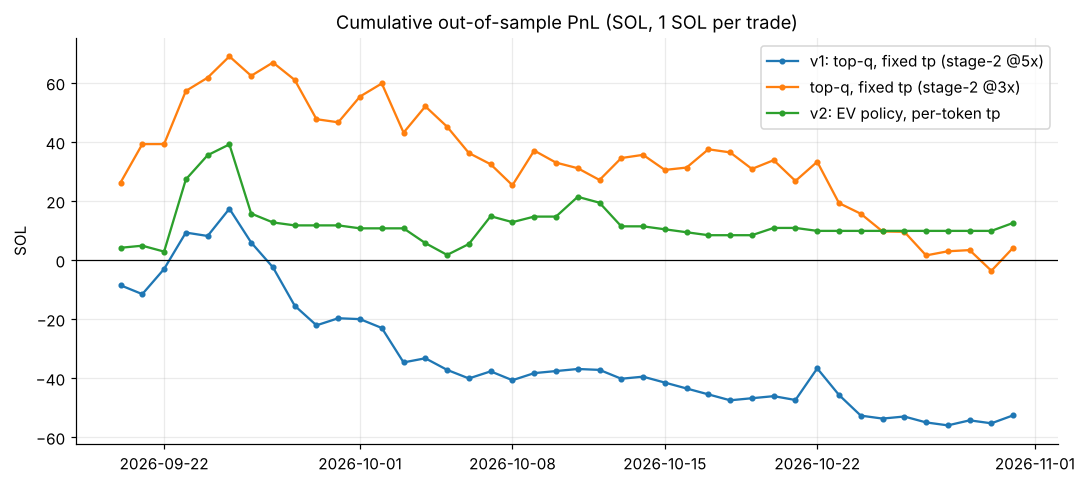


=== EV policy vs live leaderboard on 36 overlapping days ===
Our total: +0.49 SOL | leaderboard median participant (sum of daily medians): -19.71 | p90: +137.83 | best each day: +483.01
Average daily percentile vs participants: 48%
Top participants over the same days (>=80% of days scored):


,sum,size
participant,,
quantative,112.31,33
cristian034,17.98,29
yegeralan,14.90,30
muazhus,4.19,30
gorizontniy,3.08,32


In [9]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(SEED)

def summarize(df):
    rows = []
    for name, g in df.groupby('policy', sort=False):
        daily = g['pnl'].values
        boot = [rng.choice(daily, len(daily)).sum() for _ in range(5000)]   # resample whole days
        lo, hi = np.percentile(boot, [2.5, 97.5])
        t = g['trades'].sum()
        rows.append({'Policy': name, 'Days': len(g), 'Trades': t, 'Trades/day': round(t / len(g), 1),
                     'Hit rate': f"{g['hits'].sum() / max(t, 1):.1%}",
                     'Avg tp': round(np.nansum(g['mean_tp'] * g['trades']) / max(t, 1), 1),
                     'Total PnL': round(daily.sum(), 2), 'PnL/trade': f"{daily.sum() / max(t, 1):+.1%}",
                     'Profitable days': f"{(daily > 0).sum()}/{len(g)}",
                     '95% CI total': f"[{lo:+.1f}, {hi:+.1f}]"})
    return pd.DataFrame(rows)

print("=== Out-of-sample results, all report days (settings chosen on earlier days only) ===")
display(summarize(NESTED))

V1_WINDOW = [d for d in REPORT_DAYS if '2026-10-16' <= d <= '2026-10-31']
if V1_WINDOW:
    print(f"\n=== Same window as the v1 notebook ({V1_WINDOW[0]} -> {V1_WINDOW[-1]}) ===")
    print("v1 notebook reference on this window: Top 1% @5x = 59 trades, 15.3% hits, -8.94 SOL")
    display(summarize(NESTED[NESTED['day'].isin(V1_WINDOW)]))

print("\n=== Ranking quality (AUC of raw score s_k for the event max_x >= k), all walk-forward days ===")
display(pd.DataFrame([{'k': k, 'base rate': f"{(OOF['max_x'] >= k).mean():.2%}",
                       'AUC': round(roc_auc_score(OOF['max_x'] >= k, OOF[f's_{k:g}']), 3)} for k in TP_LADDER]))

print("\n=== Calibration check (predicted vs realised hit rate, by decile of calibrated probability) ===")
cal_rows = []
for k in (3.0, 5.0, 10.0):
    b = pd.qcut(EVDF[f'p_{k:g}'].rank(method='first'), 10, labels=False)
    g = EVDF.groupby(b).agg(pred=(f'p_{k:g}', 'mean'), real=('max_x', lambda s: (s >= k).mean()))
    cal_rows.append(g.iloc[[0, 4, 8, 9]].assign(k=k))
display(pd.concat(cal_rows).round(3))

ev_trades = NESTED[NESTED['policy'].str.startswith('v2')]
print("\nNested settings chosen by the EV policy (margin, cap%):", ev_trades['setting'].value_counts().head(5).to_dict())

# Cumulative PnL plot
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, g in NESTED.groupby('policy', sort=False):
    ax.plot(pd.to_datetime(g['day']), g['pnl'].cumsum(), marker='.', label=name)
ax.axhline(0, color='k', lw=0.8)
ax.set_title('Cumulative out-of-sample PnL (SOL, 1 SOL per trade)'); ax.set_ylabel('SOL'); ax.legend()
plt.tight_layout(); plt.show()

# Leaderboard comparison: same days, same tokens
if ranking_df is not None:
    rk = ranking_df[ranking_df['status'] == 'ok']
    ours = NESTED[NESTED['policy'].str.startswith('v2')][['day', 'pnl']]
    lb = rk.groupby('test_day')['pnl_day'].agg(
        lb_median='median', lb_p75=lambda s: s.quantile(.75), lb_p90=lambda s: s.quantile(.9), lb_best='max',
        n_participants='size')
    cmp_ = ours.merge(lb, left_on='day', right_index=True)
    if len(cmp_):
        cmp_['our_percentile'] = [ (rk.loc[rk['test_day'] == d, 'pnl_day'] < p).mean()
                                   for d, p in zip(cmp_['day'], cmp_['pnl'])]
        print(f"\n=== EV policy vs live leaderboard on {len(cmp_)} overlapping days ===")
        print(f"Our total: {cmp_['pnl'].sum():+.2f} SOL | leaderboard median participant (sum of daily medians): "
              f"{cmp_['lb_median'].sum():+.2f} | p90: {cmp_['lb_p90'].sum():+.2f} | best each day: {cmp_['lb_best'].sum():+.2f}")
        print(f"Average daily percentile vs participants: {cmp_['our_percentile'].mean():.0%}")
        top = rk[rk['test_day'].isin(cmp_['day'])].groupby('participant')['pnl_day'].agg(['sum', 'size'])
        top = top[top['size'] >= 0.8 * len(cmp_)].sort_values('sum', ascending=False)
        print("Top participants over the same days (>=80% of days scored):")
        display(top.head(5).round(2))


## Submission
Retrain on all labelled tokens, calibrate on all walk-forward days and use the settings with the best walk-forward PnL.

In [10]:
# Final model: train on every labelled token, calibrate on all walk-forward days,
# use the (margin, cap) with the best out-of-fold PnL across all report days.
t0 = time.time()
raw_test = multi_threshold_cascade(TR_DF, TE_DF, ALL_FEATURE_COLS)
TEST_S = TE_DF[['mint']].copy()
for k, v in raw_test.items():
    TEST_S[f's_{k:g}'] = v

cal_all, ml_all = fit_calibration(OOF)
TEST_EV = pd.concat([TEST_S, expected_values(TEST_S, cal_all, ml_all)], axis=1)
FINAL_MARGIN, FINAL_CAP = (float(x) for x in EV_GRID.sum().idxmax())
TEST_EV['tp'] = apply_ev_policy(TEST_EV.reset_index(drop=True), FINAL_MARGIN, FINAL_CAP)

submission_df = sample_sub_df[['mint']].merge(TEST_EV[['mint', 'tp']], on='mint', how='left').fillna({'tp': 0.0})
submission_df['tp'] = submission_df['tp'].astype(float)
ok = (submission_df['tp'] == 0) | submission_df['tp'].between(TP_MIN, TP_MAX)
assert ok.all() and len(submission_df) == len(sample_sub_df) and submission_df['mint'].equals(sample_sub_df['mint'])

out_paths = ['submission.csv'] + (['/kaggle/working/submission.csv'] if os.path.exists('/kaggle/working') else [])
for p in dict.fromkeys(out_paths):
    submission_df.to_csv(p, index=False)
n_buy = int((submission_df['tp'] > 0).sum())
print(f"Policy: margin={FINAL_MARGIN}, cap={FINAL_CAP}% | buys {n_buy}/{len(submission_df)} tokens "
      f"| tp used: {submission_df.loc[submission_df['tp'] > 0, 'tp'].value_counts().to_dict()} ({time.time()-t0:.0f}s)")
display(TEST_EV.loc[TEST_EV['tp'] > 0, ['mint', 'tp', 'ev'] + [f'p_{k:g}' for k in TP_LADDER]]
        .sort_values('ev', ascending=False).round(3))


Policy: margin=0.1, cap=5.0% | buys 1/409 tokens | tp used: {5.0: 1} (38s)


,mint,tp,ev,p_3,p_4,p_5,p_7,p_10,p_20
122,2GJuAJ5tj56Bvk9HQNofVefnzZmtFYGsmWs7td3Ppump,5.0,0.182,0.321,0.244,0.226,0.114,0.039,0.002
